<a href="https://colab.research.google.com/github/maliboo-wow/ml-lab/blob/main/%D0%9B%D0%A02_3_%D0%91%D1%96%D0%B1%D1%96%D0%BA%D0%BE%D0%B2%D0%B0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Лабораторна робота 2_3 Бібікова На народжуваність в Україні + 5 графіків (базовий ЕДА)

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import StringIO

Робимо імпорт бібліотек

In [2]:
url = "https://uk.wikipedia.org/wiki/Населення_України"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text

tables = pd.read_html(StringIO(html), match="народжуваності", decimal=",", thousands=" ")
print(len(tables))
df = tables[0]
df.head()

2


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


decimal="," потрібен, бо в українській Вікіпедії дробова частина пишеться через кому. Без цього параметра 13,9 може зчитатися як 139. --- це мені джеміні підказав, коли крашив блок


In [4]:
print(df.shape)
df.columns = df.columns.astype(str)
df = df.rename(columns={df.columns[0]: "Регіон"})
print(df.columns)
df.tail()

(28, 9)
Index(['Регіон', '1950', '1960', '1970', '1990', '2000', '2012', '2014',
       '2019'],
      dtype='object')


,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
23,Чернівецька,24.7,21.8,17.0,14.8,10.1,12.8,12.9,9.2
24,Чернігівська,22.0,18.3,12.7,10.8,6.9,9.4,9.0,6.1
25,Київ,NaN,17.4,15.9,12.0,7.3,12.0,12.1,11.0
26,Севастополь,NaN,NaN,NaN,12.5,7.0,12.0,—,—
27,Україна,22.8,20.5,15.2,12.6,7.8,11.4,11.1,8.1


дивимось розмір таблиці. назви колонок переводимо в текст, щоб потім було краще звертатися до них + першу колонку перейменовуємо в "Регіон", так зручніше

In [5]:
df = df.replace("—", np.nan)
print(df.dtypes)

year_cols = list(df.columns[1:])
for col in year_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)

Регіон     object
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014       object
2019       object
dtype: object
Регіон     object
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014      float64
2019      float64
dtype: object


міняємо -- на nan. після цього переводимо колонки з роками в числовий тип, бо з текстом не можна рахувати середнє і будувати графіки

In [6]:
df.isnull().mean() * 100

,0
Регіон,0.000000
1950,7.142857
1960,3.571429
1970,3.571429
1990,0.000000
2000,0.000000
2012,0.000000
2014,7.142857
2019,14.285714


рахуємо частку пропусків у кожній колонці у відсотках, щоб побачити, де і скільки даних не вистачає

In [7]:
ukraine = df[df["Регіон"] == "Україна"]
df = df[df["Регіон"] != "Україна"]
print(df.shape)

(27, 9)


 рядок "Україна" є підсумковим, а не регіоном, тому прибираємо його з таблиці, щоб він не впливав на середні значення. окремо зберігаємо його для графіка динаміки

In [12]:
print(df.mean(numeric_only=True).round(3))
df = df.fillna(df.mean(numeric_only=True))
df.isnull().sum()

1950    23.104
1960    20.758
1970    15.600
1990    13.059
2000     8.222
2012    11.656
2014    11.144
2019     8.017
dtype: float64


,0
Регіон,0
1950,0
1960,0
1970,0
1990,0
2000,0
2012,0
2014,0
2019,0


заповнюємо пропуски середнім значенням, щоб не видаляти регіони повністю. після перевіряємо, що пропусків не залишилось

In [10]:
mean_2019 = df["2019"].mean()
print(mean_2019)
df[df["2019"] > mean_2019]["Регіон"]

8.017391304347827


,Регіон
2,Волинська
6,Закарпатська
8,Івано-Франківська
12,Львівська
14,Одеська
16,Рівненська
20,Херсонська
23,Чернівецька
25,Київ


беремо останній рік у таблиці, бо він показує найактуальніші дані

In [13]:
df.sort_values("1950", ascending=False)[["Регіон", "1950"]].head(5)

,Регіон,1950
6,Закарпатська,31.4
4,Донецька,27.1
16,Рівненська,26.9
11,Луганська,26.2
5,Житомирська,26.1


In [14]:
df.sort_values("2019", ascending=False)[["Регіон", "2019"]].head(5)

,Регіон,2019
25,Київ,11.0
16,Рівненська,10.7
6,Закарпатська,10.4
2,Волинська,10.1
23,Чернівецька,9.2


дивимось, який регіон мав найвищу народжуваність у першому і в останньому році, щоб порівняти

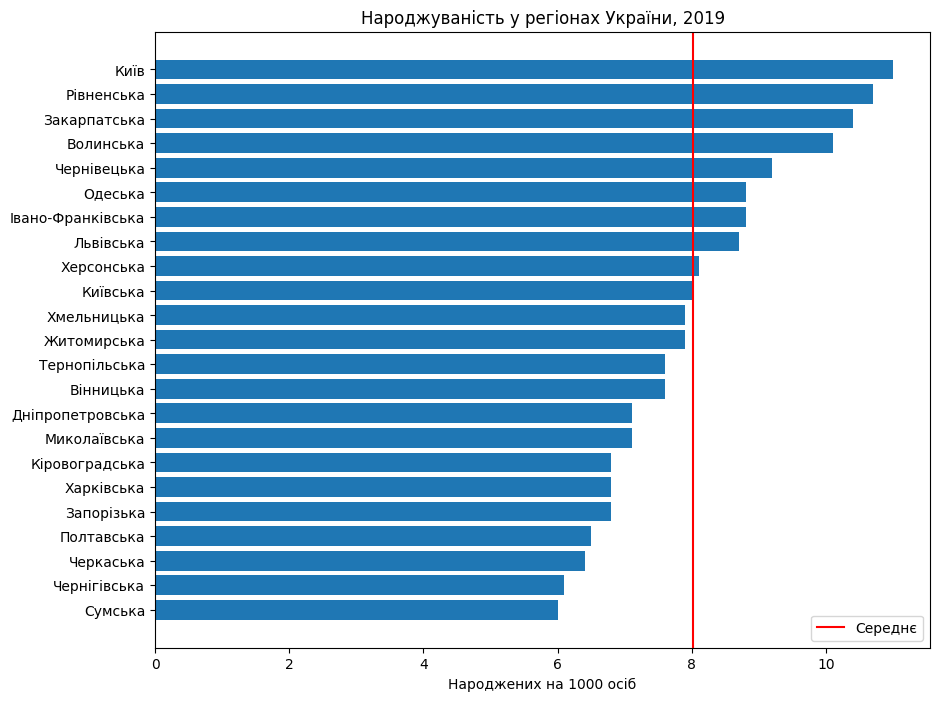

In [22]:
df_sorted = df[~df["Регіон"].isin(["Крим", "Севастополь", "Донецька", "Луганська"])].sort_values("2019")

plt.figure(figsize=(10, 8))
plt.barh(df_sorted["Регіон"], df_sorted["2019"])
plt.axvline(mean_2019, color="red", label="Середнє")
plt.title("Народжуваність у регіонах України, 2019")
plt.xlabel("Народжених на 1000 осіб")
plt.legend()
plt.show()

горизонтальна діаграма по регіонах за 2019 рік. червона лінія показує середнє значення. Крим, Севастополь, Донецьку і Луганську не показуємо, бо за 2019 по них немає даних і там стоїть середнє

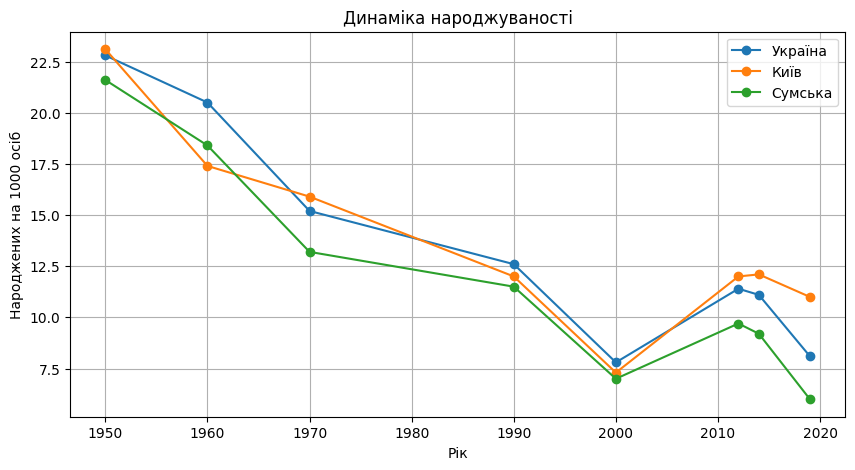

In [16]:
years = [int(y) for y in year_cols]
top = df_sorted.iloc[-1]
bottom = df_sorted.iloc[0]

plt.figure(figsize=(10, 5))
plt.plot(years, ukraine[year_cols].values[0], marker="o", label="Україна")
plt.plot(years, top[year_cols].values, marker="o", label=top["Регіон"])
plt.plot(years, bottom[year_cols].values, marker="o", label=bottom["Регіон"])
plt.title("Динаміка народжуваності")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.legend()
plt.grid()
plt.show()

лінійний графік показує, як змінювалась народжуваність з роками. для порівняння беремо україну загалом, регіон з найвищим і регіон з найнижчим значенням у 2019

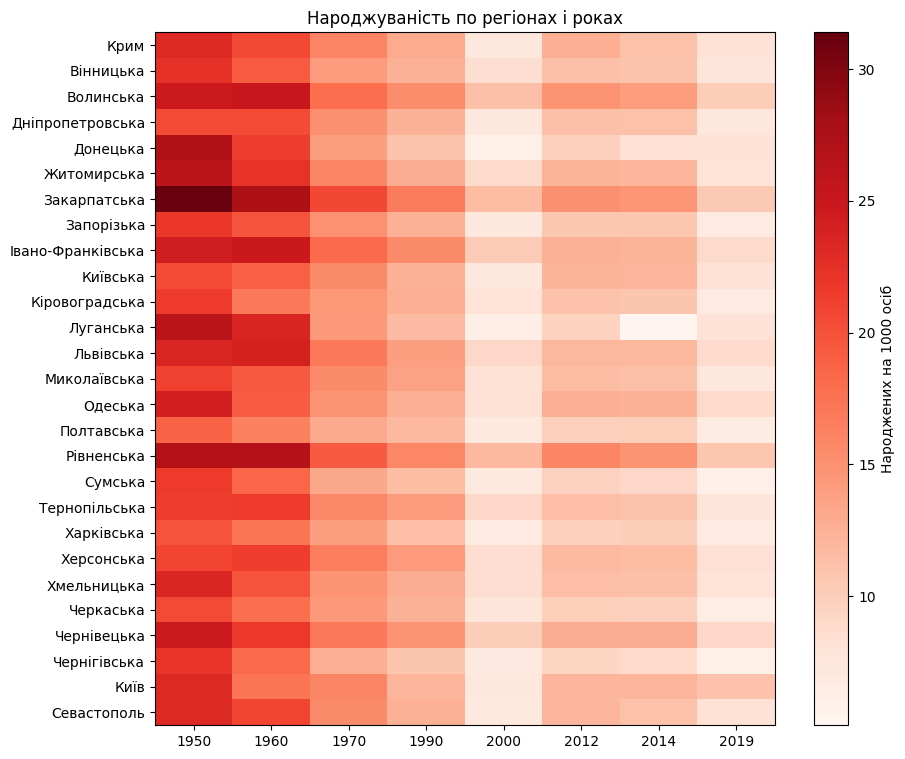

In [17]:
plt.figure(figsize=(10, 9))
plt.imshow(df[year_cols], aspect="auto", cmap="Reds")
plt.colorbar(label="Народжених на 1000 осіб")
plt.yticks(range(len(df)), df["Регіон"])
plt.xticks(range(len(year_cols)), year_cols)
plt.title("Народжуваність по регіонах і роках")
plt.show()

теплова карта показує всю таблицю одразу: чим темніший колір, тим вища народжуваність. так легко побачити загальну тенденцію по роках і різницю між регіонами

In [19]:
groups = {
    "Волинська": "Захід", "Закарпатська": "Захід", "Івано-Франківська": "Захід",
    "Львівська": "Захід", "Рівненська": "Захід", "Тернопільська": "Захід",
    "Хмельницька": "Захід", "Чернівецька": "Захід",
    "Житомирська": "Північ", "Київська": "Північ", "Київ": "Північ",
    "Сумська": "Північ", "Чернігівська": "Північ",
    "Вінницька": "Центр", "Кіровоградська": "Центр", "Полтавська": "Центр",
    "Черкаська": "Центр",
    "Дніпропетровська": "Схід", "Донецька": "Схід", "Луганська": "Схід",
    "Харківська": "Схід",
    "Запорізька": "Південь", "Миколаївська": "Південь", "Одеська": "Південь",
    "Херсонська": "Південь"
}

df["Макрорегіон"] = df["Регіон"].map(groups)
df[df["Макрорегіон"].isnull()]["Регіон"]

,Регіон
0,Крим
26,Севастополь


розподіляємо області по макрорегіонах, щоб порівняти великі частини країни між собою. крим і севастополь не включаємо, бо їхні дані після 2014 заповнені середніми

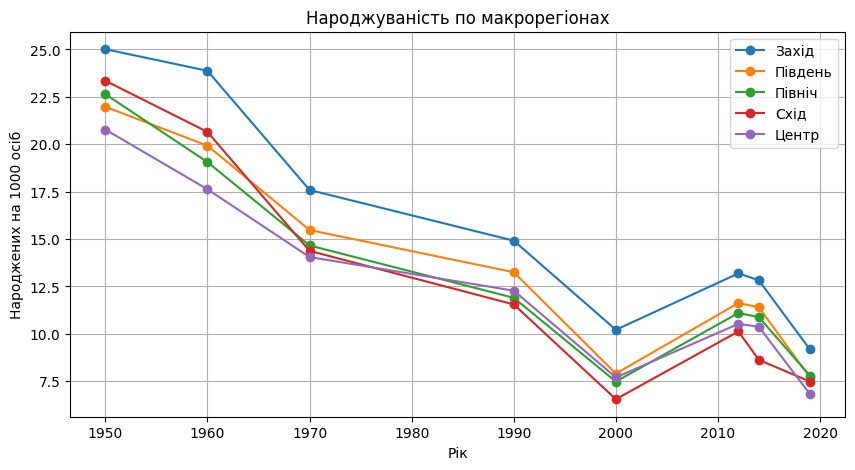

In [20]:
macro = df.groupby("Макрорегіон")[year_cols].mean()

plt.figure(figsize=(10, 5))
for name in macro.index:
    plt.plot(years, macro.loc[name], marker="o", label=name)
plt.title("Народжуваність по макрорегіонах")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.legend()
plt.grid()
plt.show()

рахуємо середню народжуваність по кожному макрорегіону і будуємо лінії по роках

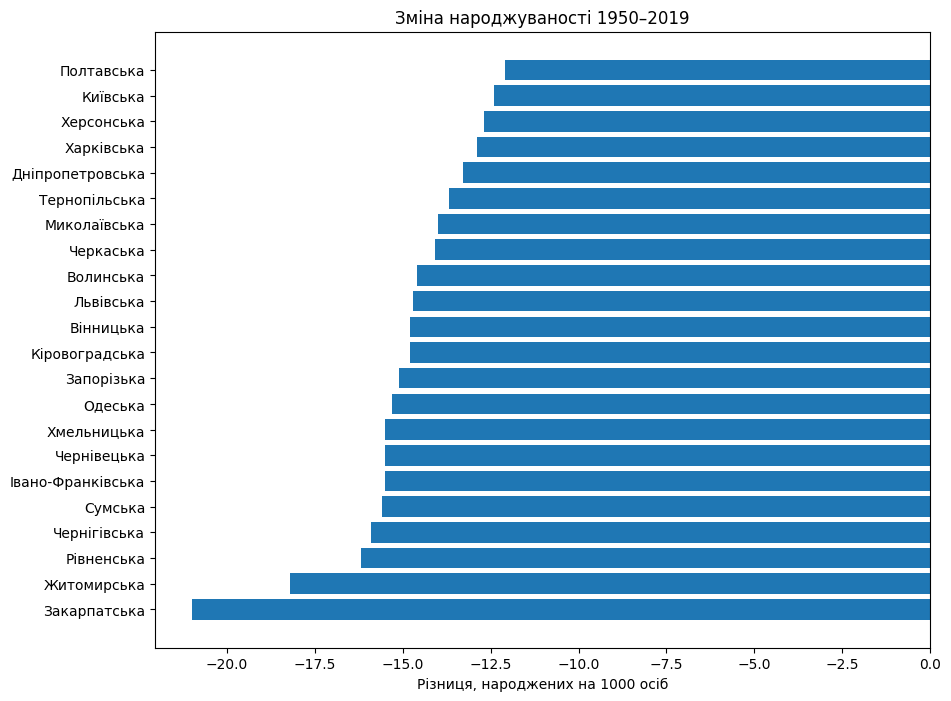

In [23]:
df["Зміна"] = df[year_cols[-1]] - df[year_cols[0]]
df_change = df[~df["Регіон"].isin(["Крим", "Севастополь", "Донецька", "Луганська", "Київ"])].sort_values("Зміна")

plt.figure(figsize=(10, 8))
plt.barh(df_change["Регіон"], df_change["Зміна"])
plt.title(f"Зміна народжуваності {year_cols[0]}–{year_cols[-1]}")
plt.xlabel("Різниця, народжених на 1000 осіб")
plt.show()

рахуємо різницю між останнім і першим роком для кожного регіону і будуємо діаграму, щоб побачити, де народжуваність впала найбільше. регіони, де у 1950 або 2019 був пропуск, не беремо, бо різниця для них вийде неправильною

Висновки

- народжуваність в україні за 1950-2019 впала майже втричі: з 22.8 до 8.1 на 1000 осіб
- найнижча точка була у 2000 році (7.8), до 2012 був ріст до 11.4, а після 2014 знову падіння
- у 2019 вище середнього (8.02) було 9 регіонів: 6 західних областей, Київ, одеська і херсонська
- лідер змінився: у 1950 це закарпатська (31.4), у 2019 Київ (11.0), а закарпатська вже третя (10.4). найнижча народжуваність у 2019 у сумській і чернігівській, близько 6
- найбільше народжуваність впала у закарпатській (-21) і житомирській (-18), найменше у полтавській (близько -12)
- захід має найвищу народжуваність серед макрорегіонів у всі роки: 25.0 у 1950 і 9.2 у 2019
- у 1950 різниця між найвищим (захід, 25.0) і найнижчим (центр, 20.7) макрорегіоном була приблизно 4.3, у 2019 (захід 9.2, центр 6.8) приблизно 2.4, тобто регіони стали ближчими між собою
- схід у 1950-1960 був другим після заходу (23.3 і 20.6), але з 1970 опустився до рівня інших, а у 2000 мав найнижче значення (6.5)
- з 2012 по 2014 найсильніше впав схід, з 10.1 до 8.6, тоді як інші макрорегіони майже не змінились. це збігається з початком війни у 2014
- у 2019 немає даних по Криму, Севастополю, донецькій і луганській, а у 1950 по києву і севастополю. пропуски заповнені середніми, тому значення києва за 1950 на графіку динаміки і сходу за 2019 на графіку макрорегіонів умовні